In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# **STEP 1: PROJECT SETUP AND DATASET AUDIT**

DATASET ROOT: /content/drive/MyDrive/Dataset

Total images: 11,577
Total source groups: 34


,class_name,image_count,source_group_count
0,Class 1,1581,5
1,Class 2,2699,8
2,Class 3,2794,8
3,Class 4,2897,8
4,Class 5,1606,5



Sampled image dimensions (width, height):
[((500, 500), 100)]


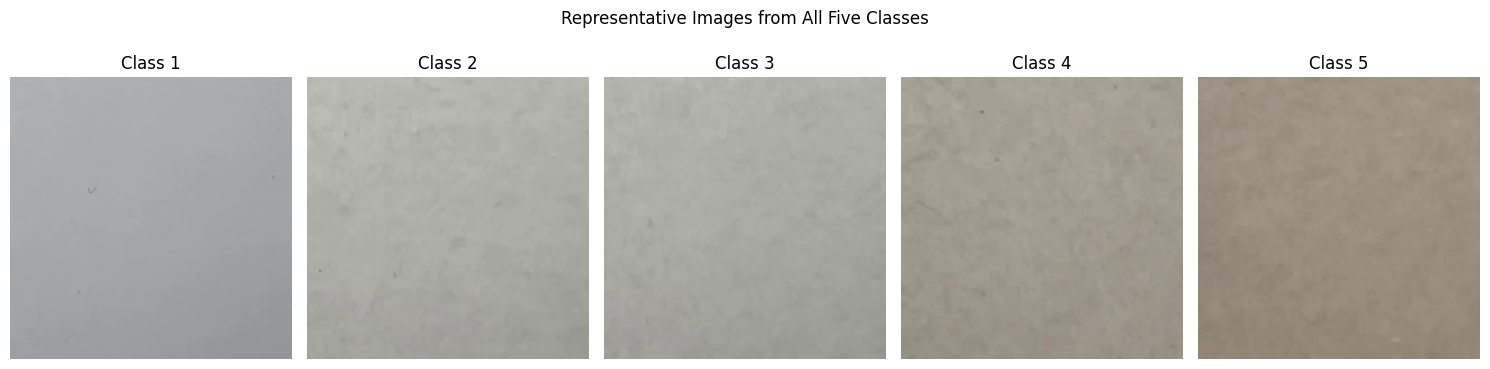

In [ ]:
from pathlib import Path
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display as show_table

PROJECT_CLASSES = [f"Class {i}" for i in range(1, 6)]

# Find the existing dataset
candidate_roots = [
    Path("/content/Dataset"),
    Path("/content/drive/MyDrive/Dataset")
]

DATASET_ROOT = next(
    (
        path for path in candidate_roots
        if all((path / cls).is_dir() for cls in PROJECT_CLASSES)
    ),
    None
)

if DATASET_ROOT is None:
    raise FileNotFoundError(
        "Dataset not found. Ensure /content/Dataset or "
        "/content/drive/MyDrive/Dataset contains Class 1 to Class 5."
    )

print("DATASET ROOT:", DATASET_ROOT)

# Build an image index
valid_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
records = []

for label, class_name in enumerate(PROJECT_CLASSES):
    class_dir = DATASET_ROOT / class_name

    for path in sorted(class_dir.rglob("*")):
        if path.is_file() and path.suffix.lower() in valid_extensions:
            # Frames from the same source share the same source group
            source_group = path.stem.split("_frame_")[0]

            records.append({
                "filepath": str(path),
                "filename": path.name,
                "class_name": class_name,
                "label": label,
                "source_group": source_group
            })

project_df = pd.DataFrame(records)

if project_df.empty:
    raise ValueError("No supported image files were found.")

# Summarize dataset distribution
summary = (
    project_df.groupby("class_name")
    .agg(
        image_count=("filepath", "count"),
        source_group_count=("source_group", "nunique")
    )
    .reindex(PROJECT_CLASSES)
    .reset_index()
)

print(f"\nTotal images: {len(project_df):,}")
print(f"Total source groups: {project_df['source_group'].nunique()}")
show_table(summary)

# Inspect image dimensions on a small sample
dimension_samples = project_df.groupby("class_name").head(20)
dimensions = []

for filepath in dimension_samples["filepath"]:
    with Image.open(filepath) as img:
        dimensions.append(img.size)

print("\nSampled image dimensions (width, height):")
print(Counter(dimensions).most_common(10))

# Display one sample from each class
fig, axes = plt.subplots(1, 5, figsize=(15, 4))

for label, ax in enumerate(axes):
    sample = project_df[project_df["label"] == label].iloc[0]

    with Image.open(sample["filepath"]) as img:
        ax.imshow(img.convert("RGB"))

    ax.set_title(sample["class_name"])
    ax.axis("off")

plt.suptitle("Representative Images from All Five Classes")
plt.tight_layout()
plt.show()

# **STEP 2: TURBIDITY KNOWLEDGE BASE AND LABEL VALIDATION**

In [ ]:

class_info = pd.DataFrame({
    "Class": ["Class 1", "Class 2", "Class 3", "Class 4", "Class 5"],
    "Water Quality": [
        "Excellent quality",
        "Good quality",
        "Acceptable quality",
        "Contaminated",
        "Highly contaminated"
    ],
    "Turbidity Range (NTU)": [
        "0–7", "10–25", "30–55", "60–120", "140–180"
    ]
})

print("TURBIDITY CLASSIFICATION KNOWLEDGE BASE")
show_table(class_info)

# Check whether each source group belongs to exactly one class
groups_per_class = project_df.groupby("source_group")["class_name"].nunique()
mixed_groups = groups_per_class[groups_per_class > 1]

print("\nDATA INTEGRITY CHECK")
print("Unique source groups:", project_df["source_group"].nunique())
print("Groups containing multiple class labels:", len(mixed_groups))

# Confirm all five classes are present
print("All five classes present:",
      set(project_df["class_name"].unique()) == set(PROJECT_CLASSES))

TURBIDITY CLASSIFICATION KNOWLEDGE BASE


,Class,Water Quality,Turbidity Range (NTU)
0,Class 1,Excellent quality,0–7
1,Class 2,Good quality,10–25
2,Class 3,Acceptable quality,30–55
3,Class 4,Contaminated,60–120
4,Class 5,Highly contaminated,140–180



DATA INTEGRITY CHECK
Unique source groups: 34
Groups containing multiple class labels: 0
All five classes present: True


# **STEP 3: IMAGE ENHANCEMENT**

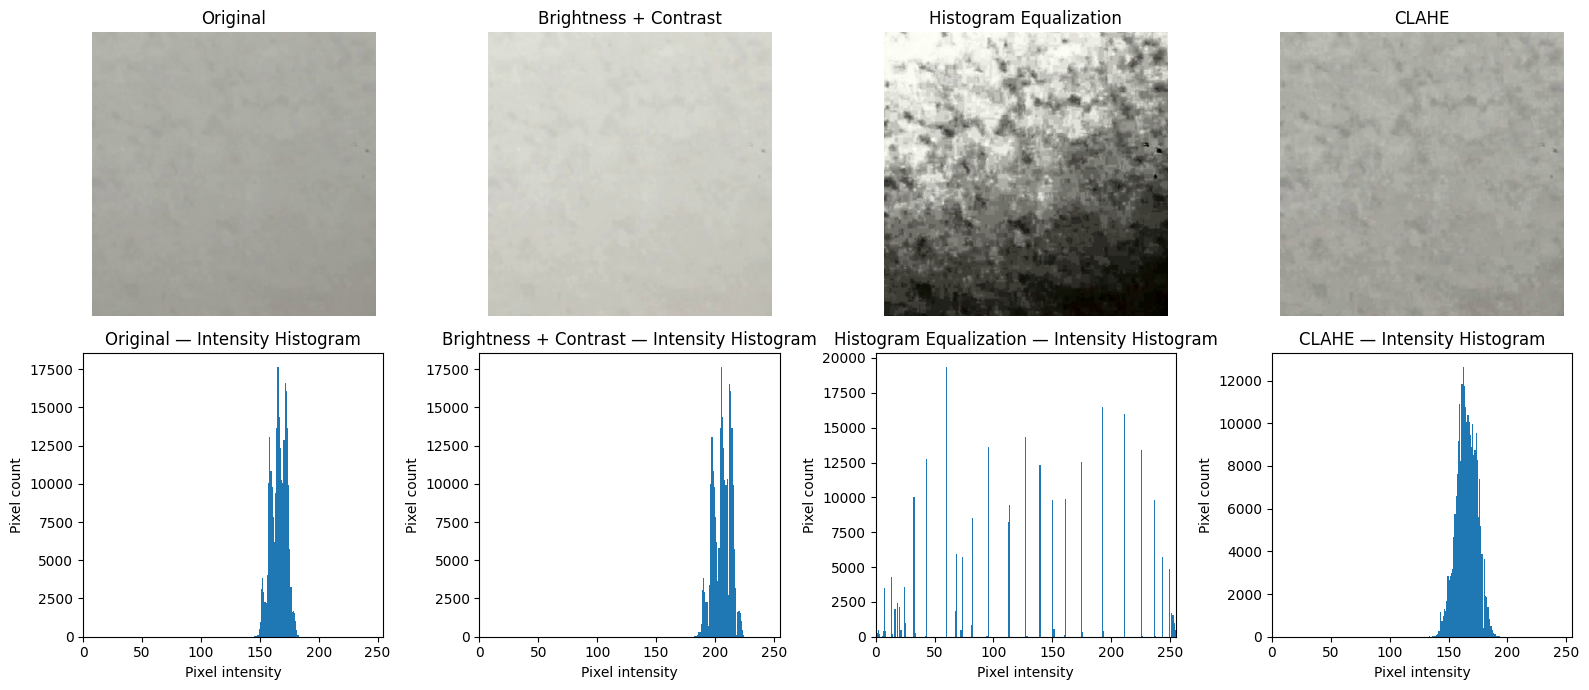

Enhancement comparison completed


In [ ]:


import cv2
import numpy as np
import matplotlib.pyplot as plt

sample_row = (
    project_df[project_df["class_name"] == "Class 3"]
    .sample(1, random_state=42)
    .iloc[0]
)

img_bgr = cv2.imread(sample_row["filepath"])

if img_bgr is None:
    raise ValueError("Could not read the selected image.")

original = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

bright_contrast = cv2.convertScaleAbs(
    original, alpha=1.15, beta=15
)

lab = cv2.cvtColor(original, cv2.COLOR_RGB2LAB)
L, A, B = cv2.split(lab)

equalized_L = cv2.equalizeHist(L)
hist_equalized = cv2.cvtColor(
    cv2.merge([equalized_L, A, B]),
    cv2.COLOR_LAB2RGB
)

# Contrast Limited Adaptive Histogram Equalization
clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

clahe_L = clahe.apply(L)
clahe_image = cv2.cvtColor(
    cv2.merge([clahe_L, A, B]),
    cv2.COLOR_LAB2RGB
)

images = [
    ("Original", original),
    ("Brightness + Contrast", bright_contrast),
    ("Histogram Equalization", hist_equalized),
    ("CLAHE", clahe_image)
]

fig, axes = plt.subplots(2, 4, figsize=(16, 7))

for i, (title, image) in enumerate(images):
    axes[0, i].imshow(image)
    axes[0, i].set_title(title)
    axes[0, i].axis("off")

    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    axes[1, i].hist(gray.ravel(), bins=256, range=(0, 256))
    axes[1, i].set_title(f"{title} — Intensity Histogram")
    axes[1, i].set_xlim(0, 255)
    axes[1, i].set_xlabel("Pixel intensity")
    axes[1, i].set_ylabel("Pixel count")

plt.tight_layout()
plt.show()

print("Enhancement comparison completed")

# **STEP 4: IMAGE RESTORATION AND DENOISING**

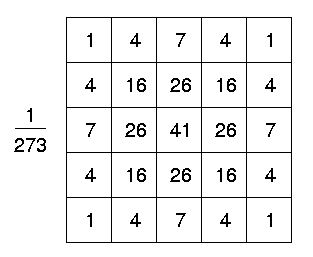

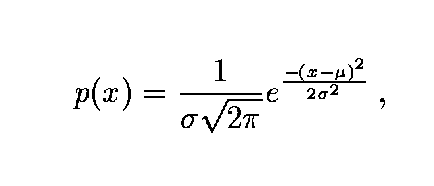

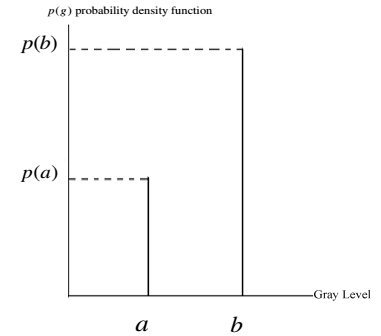,
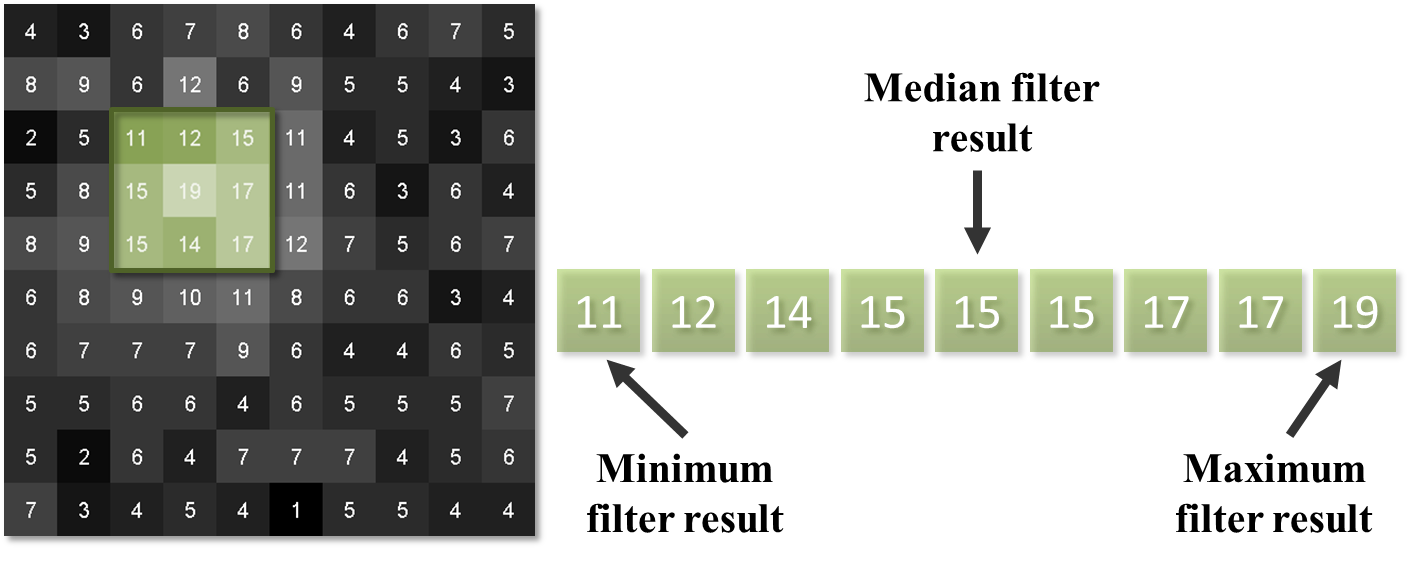

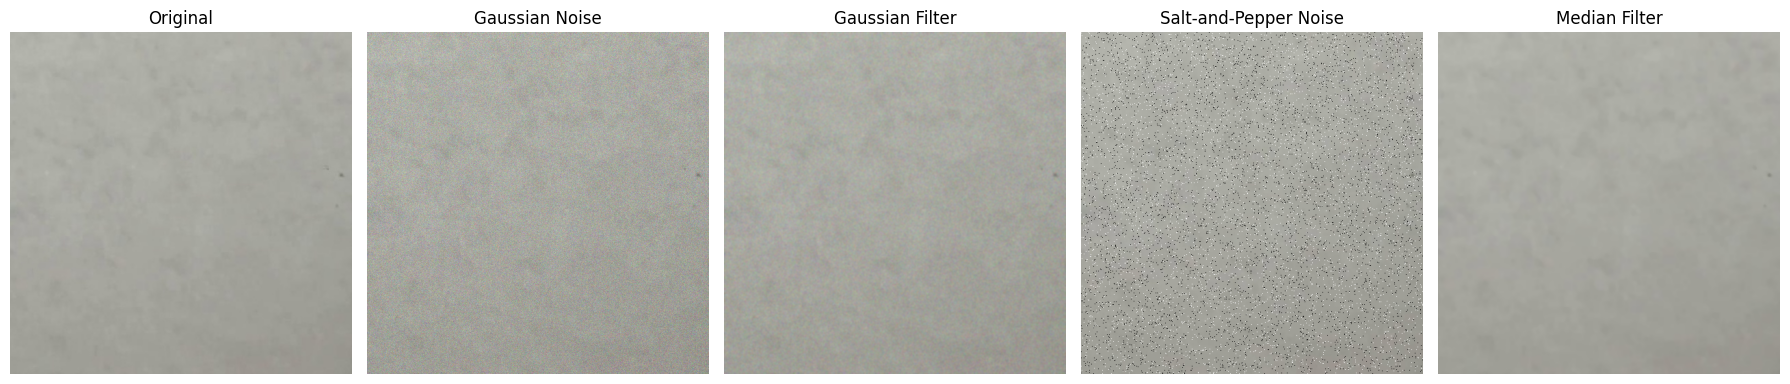

,Image,PSNR (dB)
0,Gaussian noisy,26.530001
1,After Gaussian filter,37.169998
2,Salt-and-pepper noisy,19.570000
3,After median filter,52.860001


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

original_uint8 = original.copy()
rng = np.random.default_rng(42)

noise = rng.normal(
    0, 12, original_uint8.shape
)
gaussian_noisy = np.clip(
    original_uint8.astype(np.float32) + noise,
    0, 255
).astype(np.uint8)

gaussian_restored = cv2.GaussianBlur(
    gaussian_noisy, (5, 5), 1.0
)

salt_pepper_noisy = original_uint8.copy()
mask = rng.random(original_uint8.shape[:2])
salt_pepper_noisy[mask < 0.02] = 0
salt_pepper_noisy[mask > 0.98] = 255

median_restored = cv2.medianBlur(
    salt_pepper_noisy, 5
)

results = [
    ("Original", original_uint8),
    ("Gaussian Noise", gaussian_noisy),
    ("Gaussian Filter", gaussian_restored),
    ("Salt-and-Pepper Noise", salt_pepper_noisy),
    ("Median Filter", median_restored)
]

fig, axes = plt.subplots(1, 5, figsize=(18, 4))

for ax, (title, img) in zip(axes, results):
    ax.imshow(img)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

# peak signal to noise ratio
def calculate_psnr(reference, processed):
    mse = np.mean(
        (reference.astype(np.float32) -
         processed.astype(np.float32)) ** 2
    )
    return float("inf") if mse == 0 else 10 * np.log10(255**2 / mse)

restoration_results = pd.DataFrame({
    "Image": [
        "Gaussian noisy",
        "After Gaussian filter",
        "Salt-and-pepper noisy",
        "After median filter"
    ],
    "PSNR (dB)": [
        calculate_psnr(original_uint8, gaussian_noisy),
        calculate_psnr(original_uint8, gaussian_restored),
        calculate_psnr(original_uint8, salt_pepper_noisy),
        calculate_psnr(original_uint8, median_restored)
    ]
})

show_table(restoration_results.round(2))
# Higher PSNR indicates lower error relative to the original

# **STEP 5: COLOR IMAGE PROCESSING**

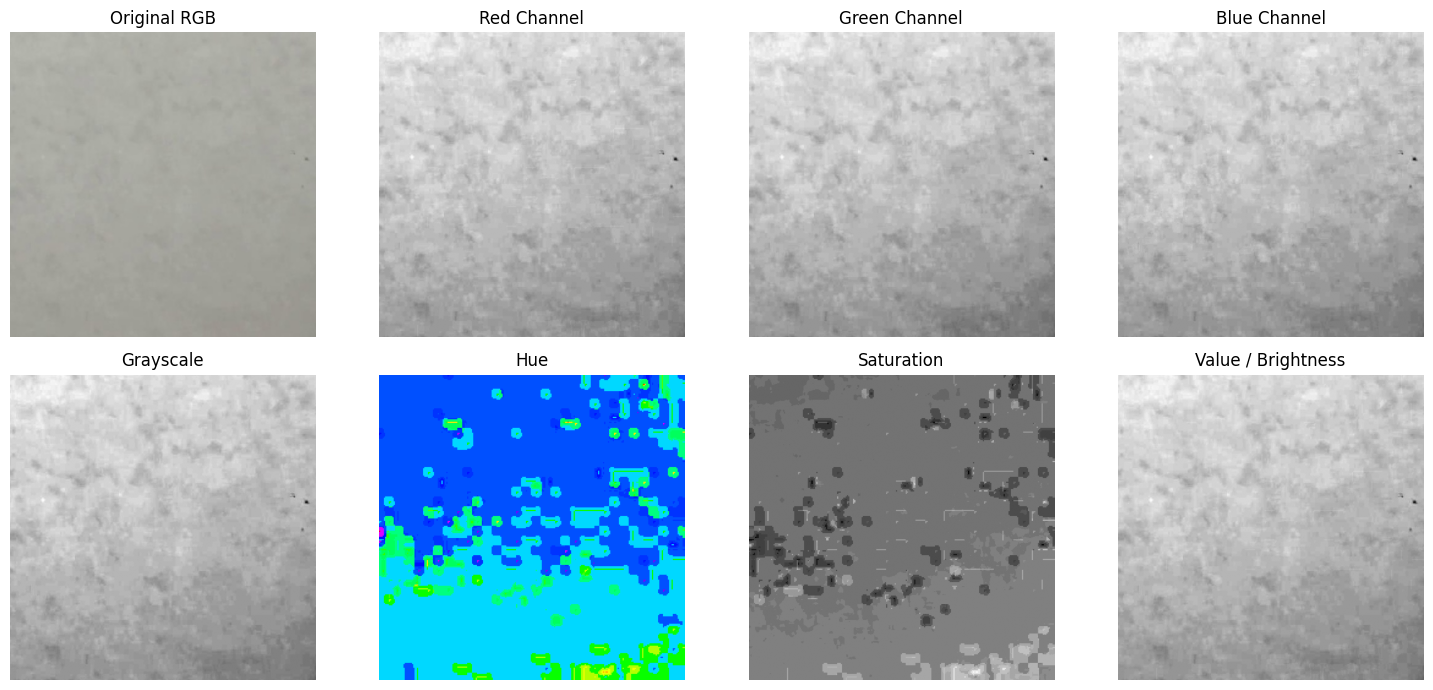

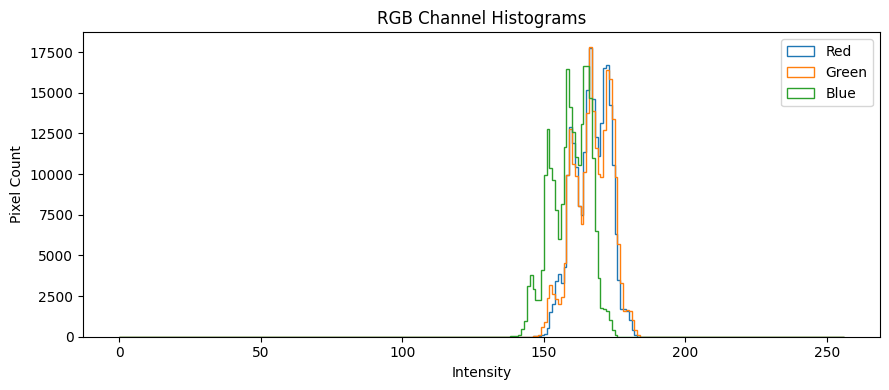

,Feature,Value
0,Red mean,166.244
1,Green mean,166.512
2,Blue mean,158.842
3,Red std,6.128
4,Green std,6.675
5,Blue std,6.654
6,Grayscale mean,165.628
7,Grayscale std,6.584
8,Mean saturation,12.145
9,Mean value,166.738


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

rgb = original.copy()
gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)

red, green, blue = cv2.split(rgb)
hue, saturation, value = cv2.split(hsv)

fig, axes = plt.subplots(2, 4, figsize=(15, 7))

display_images = [
    ("Original RGB", rgb, None),
    ("Red Channel", red, "gray"),
    ("Green Channel", green, "gray"),
    ("Blue Channel", blue, "gray"),
    ("Grayscale", gray, "gray"),
    ("Hue", hue, "hsv"),
    ("Saturation", saturation, "gray"),
    ("Value / Brightness", value, "gray")
]

for ax, (title, image, cmap) in zip(axes.flat, display_images):
    ax.imshow(image, cmap=cmap)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 4))

for channel, name in zip(
    [red, green, blue], ["Red", "Green", "Blue"]
):
    plt.hist(
        channel.ravel(), bins=256, range=(0, 256),
        histtype="step", label=name
    )

plt.title("RGB Channel Histograms")
plt.xlabel("Intensity")
plt.ylabel("Pixel Count")
plt.legend()
plt.tight_layout()
plt.show()

color_features = {
    "Red mean": red.mean(),
    "Green mean": green.mean(),
    "Blue mean": blue.mean(),
    "Red std": red.std(),
    "Green std": green.std(),
    "Blue std": blue.std(),
    "Grayscale mean": gray.mean(),
    "Grayscale std": gray.std(),
    "Mean saturation": saturation.mean(),
    "Mean value": value.mean()
}

color_feature_table = pd.DataFrame({
    "Feature": color_features.keys(),
    "Value": color_features.values()
})

display(color_feature_table.round(3))

# STEP 6: WAVELET IMAGE **PROCESSING**

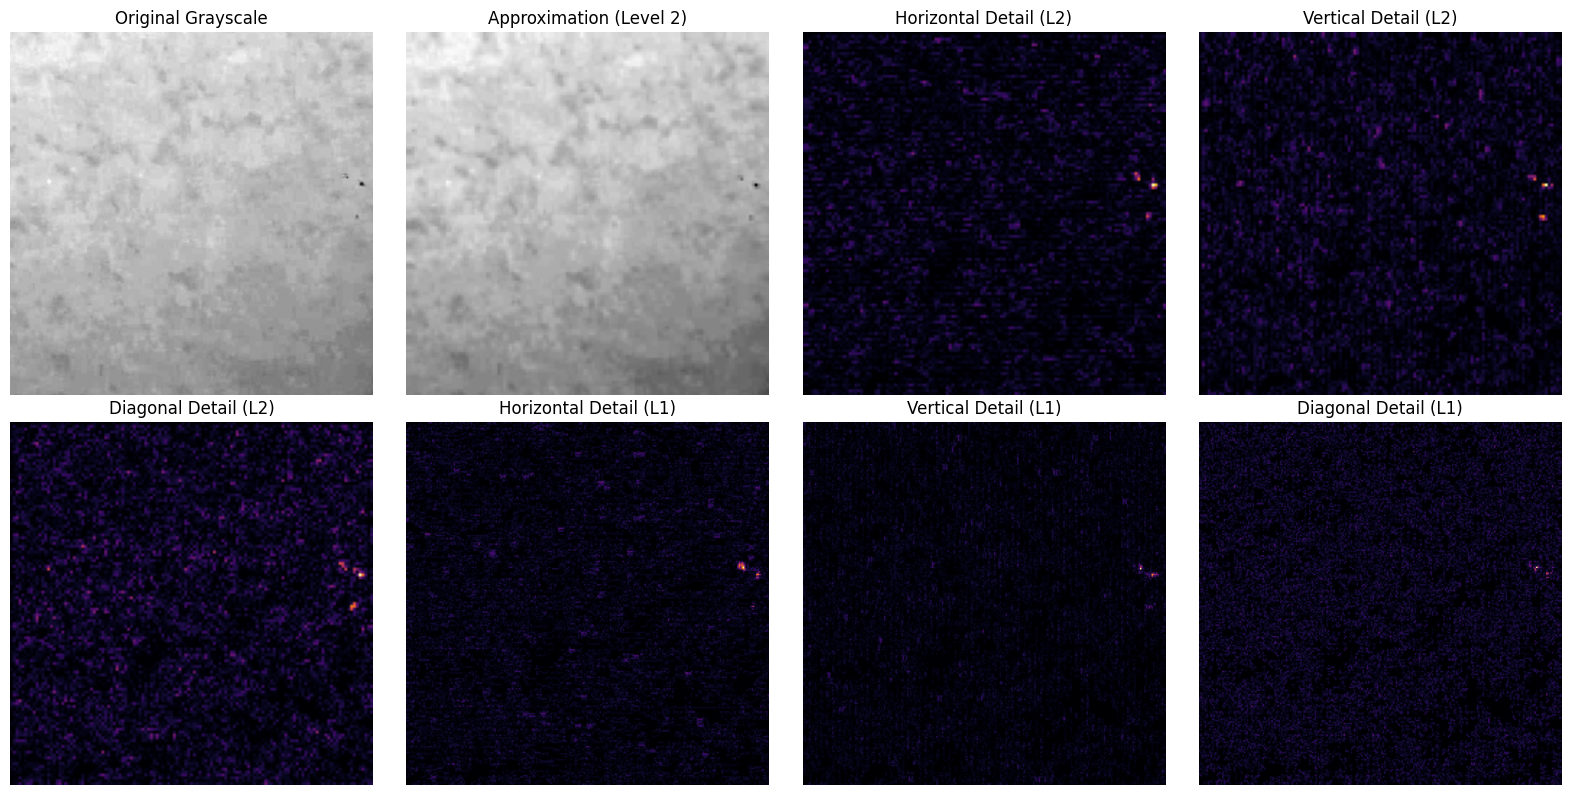

,Component,Coefficient Count,Energy,Mean Absolute Coefficient
0,Approximation L2,16129,7.095188e+09,662.72
1,Horizontal Detail L2,16129,2.867468e+04,0.92
2,Vertical Detail L2,16129,2.668096e+04,0.91
3,Diagonal Detail L2,16129,3.967190e+03,0.36
4,Horizontal Detail L1,63001,1.242201e+04,0.30
5,Vertical Detail L1,63001,1.222478e+04,0.30
6,Diagonal Detail L1,63001,4.422970e+03,0.18


Two-level DWT completed using the db2 wavelet


In [ ]:
%pip -q install PyWavelets

import pywt
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2

gray_float = gray.astype(np.float32)

wavelet_name = "db2"
coefficients = pywt.wavedec2(
    gray_float,
    wavelet=wavelet_name,
    level=2
)

cA2 = coefficients[0]
cH2, cV2, cD2 = coefficients[1]
cH1, cV1, cD1 = coefficients[2]

def normalize_detail(detail):
    detail = np.abs(detail)
    maximum = detail.max()

    if maximum == 0:
        return np.zeros_like(detail)

    return detail / maximum

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

wavelet_images = [
    ("Original Grayscale", gray_float, "gray"),
    ("Approximation (Level 2)", cA2, "gray"),
    ("Horizontal Detail (L2)", normalize_detail(cH2), "inferno"),
    ("Vertical Detail (L2)", normalize_detail(cV2), "inferno"),
    ("Diagonal Detail (L2)", normalize_detail(cD2), "inferno"),
    ("Horizontal Detail (L1)", normalize_detail(cH1), "inferno"),
    ("Vertical Detail (L1)", normalize_detail(cV1), "inferno"),
    ("Diagonal Detail (L1)", normalize_detail(cD1), "inferno")
]

for ax, (title, image, cmap) in zip(axes.flat, wavelet_images):
    ax.imshow(image, cmap=cmap)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

components = {
    "Approximation L2": cA2,
    "Horizontal Detail L2": cH2,
    "Vertical Detail L2": cV2,
    "Diagonal Detail L2": cD2,
    "Horizontal Detail L1": cH1,
    "Vertical Detail L1": cV1,
    "Diagonal Detail L1": cD1
}

wavelet_energy = pd.DataFrame([
    {
        "Component": name,
        "Coefficient Count": values.size,
        "Energy": float(np.sum(values.astype(np.float64) ** 2)),
        "Mean Absolute Coefficient": float(np.mean(np.abs(values)))
    }
    for name, values in components.items()
])

show_table(wavelet_energy.round(2))
print("Two-level DWT completed using the", wavelet_name, "wavelet")

# STEP 7: IMAGE **COMPRESSION**

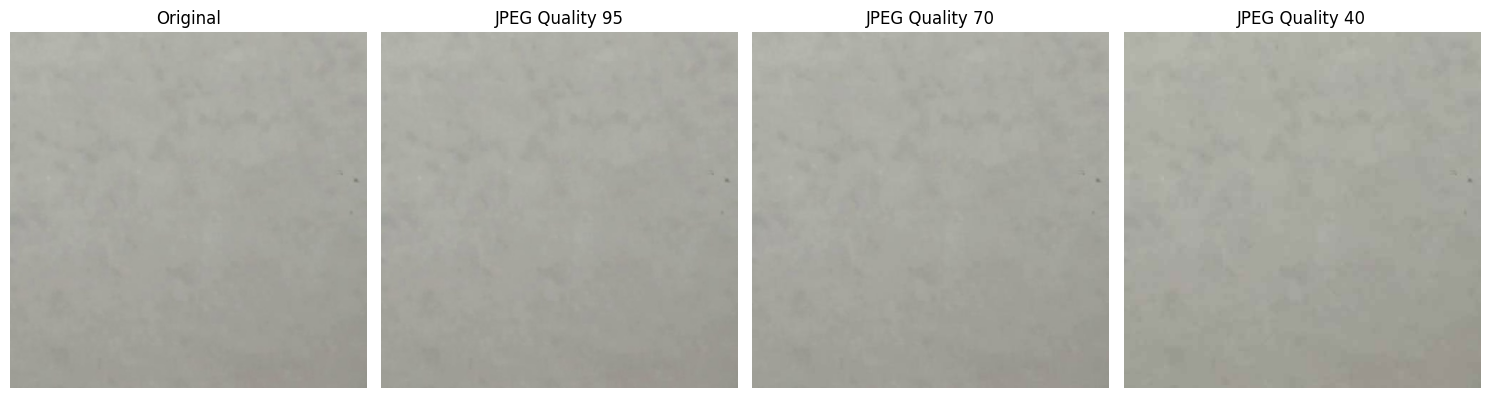

,JPEG Quality,File Size (KB),Raw RGB Size (KB),Size Reduction vs Raw (%),PSNR (dB)
0,95,26.05,732.42,96.44,63.570000
1,70,8.08,732.42,98.90,48.040001
2,40,5.68,732.42,99.22,43.119999


In [ ]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

compression_original = original.copy()
raw_size_bytes = compression_original.nbytes

qualities = [95, 70, 40]
compression_results = []
compressed_images = [("Original", compression_original)]

for quality in qualities:
    bgr = cv2.cvtColor(compression_original, cv2.COLOR_RGB2BGR)

    success, encoded = cv2.imencode(
        ".jpg",
        bgr,
        [cv2.IMWRITE_JPEG_QUALITY, quality]
    )

    if not success:
        raise RuntimeError(f"JPEG encoding failed at quality {quality}.")

    decoded_bgr = cv2.imdecode(encoded, cv2.IMREAD_COLOR)
    decoded_rgb = cv2.cvtColor(decoded_bgr, cv2.COLOR_BGR2RGB)

    file_size = len(encoded)
    mse = np.mean(
        (compression_original.astype(np.float32) -
         decoded_rgb.astype(np.float32)) ** 2
    )
    psnr = float("inf") if mse == 0 else 10 * np.log10(255**2 / mse)

    compression_results.append({
        "JPEG Quality": quality,
        "File Size (KB)": file_size / 1024,
        "Raw RGB Size (KB)": raw_size_bytes / 1024,
        "Size Reduction vs Raw (%)":
            (1 - file_size / raw_size_bytes) * 100,
        "PSNR (dB)": psnr
    })

    compressed_images.append((f"JPEG Quality {quality}", decoded_rgb))

fig, axes = plt.subplots(1, 4, figsize=(15, 4))

for ax, (title, image) in zip(axes, compressed_images):
    ax.imshow(image)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

compression_table = pd.DataFrame(compression_results)
display(compression_table.round(2))

# STEP 8: MORPHOLOGICAL IMAGE **PROCESSING**

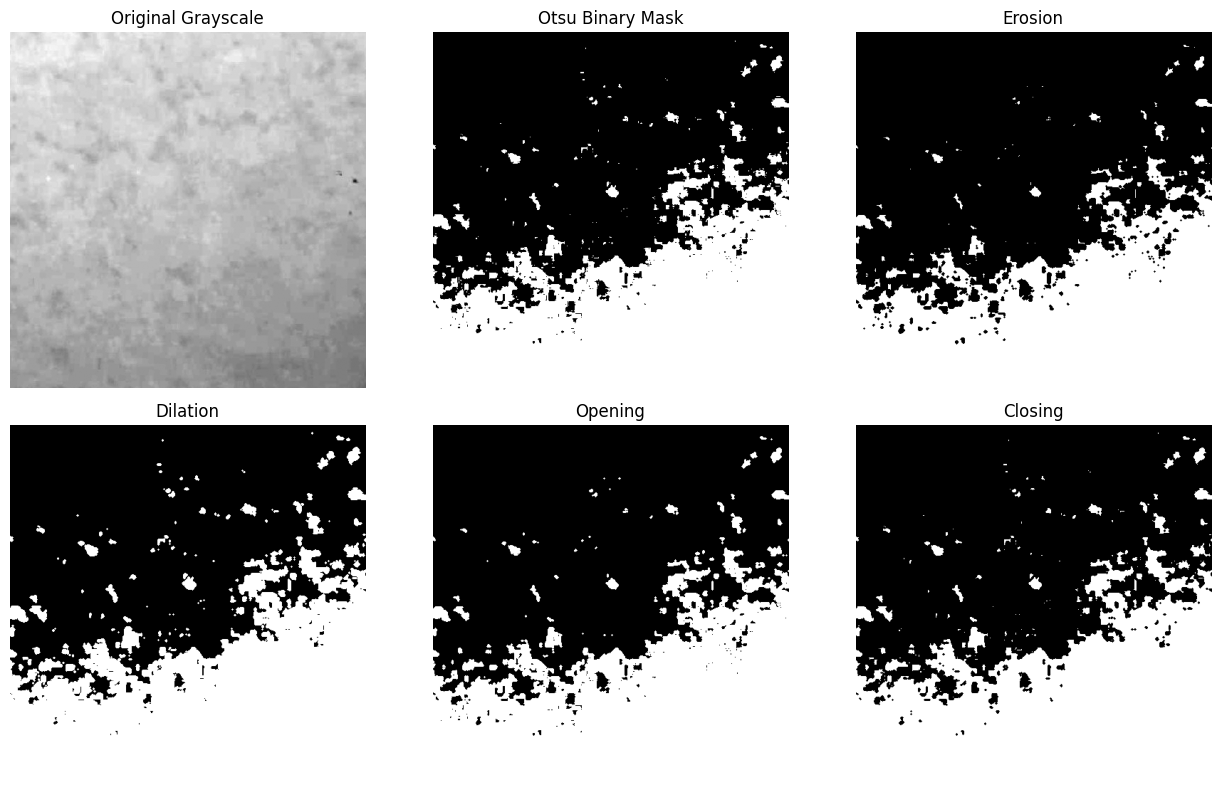

,Operation,Foreground pixels,Foreground percentage
0,Threshold mask,100888,40.36
1,Erosion,94140,37.66
2,Dilation,107715,43.09
3,Opening,99894,39.96
4,Closing,101785,40.71


Erosion shrinks foreground regions
Dilation expands foreground regions
Opening removes small foreground details
Closing fills small gaps in foreground regions
Thresholded dark regions are not necessarily water or contaminants


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

gray_morph = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY)

_, binary_mask = cv2.threshold(
    gray_morph, 0, 255,
    cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)

kernel = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE, (3, 3)
)

eroded = cv2.erode(binary_mask, kernel, iterations=1)
dilated = cv2.dilate(binary_mask, kernel, iterations=1)
opened = cv2.morphologyEx(
    binary_mask, cv2.MORPH_OPEN, kernel
)
closed = cv2.morphologyEx(
    binary_mask, cv2.MORPH_CLOSE, kernel
)

results = [
    ("Original Grayscale", gray_morph),
    ("Otsu Binary Mask", binary_mask),
    ("Erosion", eroded),
    ("Dilation", dilated),
    ("Opening", opened),
    ("Closing", closed)
]

fig, axes = plt.subplots(2, 3, figsize=(13, 8))

for ax, (title, image) in zip(axes.flat, results):
    ax.imshow(image, cmap="gray")
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

masks = {
    "Threshold mask": binary_mask,
    "Erosion": eroded,
    "Dilation": dilated,
    "Opening": opened,
    "Closing": closed
}

morph_summary = pd.DataFrame([
    {
        "Operation": name,
        "Foreground pixels": int(np.count_nonzero(mask)),
        "Foreground percentage": 100 * np.count_nonzero(mask) / mask.size
    }
    for name, mask in masks.items()
])

display(morph_summary.round(2))

print("Erosion shrinks foreground regions")
print("Dilation expands foreground regions")
print("Opening removes small foreground details")
print("Closing fills small gaps in foreground regions")
print("Thresholded dark regions are not necessarily water or contaminants")

# **STEP 9: IMAGE SEGMENTATION**

* otsu thresholding
* adaptive thresholding
* K-mean clustering



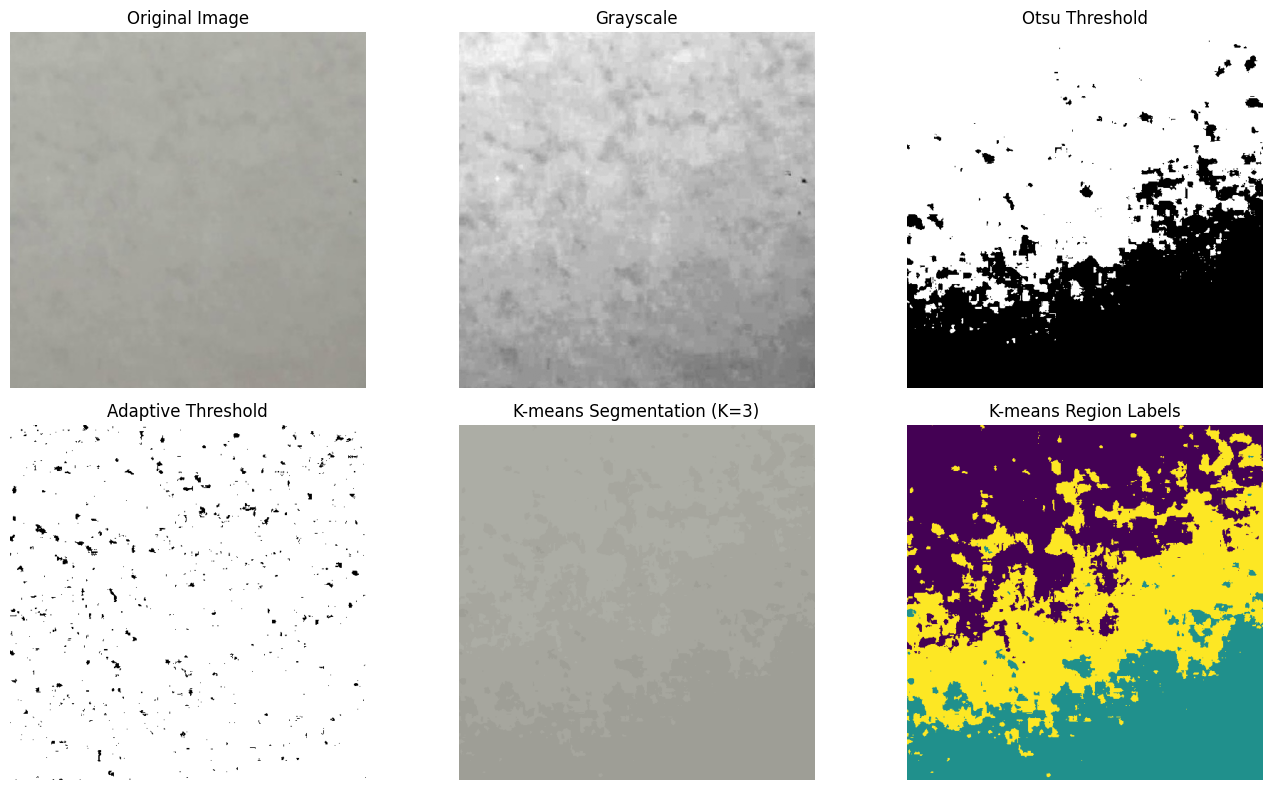

Otsu threshold intensity: 164

K-means cluster distribution:
Cluster 0: 88,081 pixels (35.23%)
Cluster 1: 71,204 pixels (28.48%)
Cluster 2: 90,715 pixels (36.29%)

Interpretation:
Thresholding separates pixels by intensity.
K-means groups pixels by color similarity.
These segments are not verified water or contaminant regions.


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = original.copy()
gray_seg = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

otsu_threshold, otsu_mask = cv2.threshold(
    gray_seg, 0, 255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

adaptive_mask = cv2.adaptiveThreshold(
    gray_seg, 255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    31, 3
)

pixels = img.reshape((-1, 3)).astype(np.float32)

criteria = (
    cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER,
    100,
    0.2
)

_, labels, centers = cv2.kmeans(
    pixels,
    3,
    None,
    criteria,
    5,
    cv2.KMEANS_PP_CENTERS
)

centers = np.uint8(centers)
segmented_rgb = centers[labels.flatten()].reshape(img.shape)
label_map = labels.reshape(gray_seg.shape)

fig, axes = plt.subplots(2, 3, figsize=(14, 8))

plots = [
    ("Original Image", img, None),
    ("Grayscale", gray_seg, "gray"),
    ("Otsu Threshold", otsu_mask, "gray"),
    ("Adaptive Threshold", adaptive_mask, "gray"),
    ("K-means Segmentation (K=3)", segmented_rgb, None),
    ("K-means Region Labels", label_map, "viridis")
]

for ax, (title, image, cmap) in zip(axes.flat, plots):
    ax.imshow(image, cmap=cmap)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

print(f"Otsu threshold intensity: {otsu_threshold:.0f}")

print("\nK-means cluster distribution:")
unique_labels, counts = np.unique(labels, return_counts=True)

for cluster_id, count in zip(unique_labels, counts):
    print(
        f"Cluster {cluster_id}: "
        f"{count:,} pixels ({100 * count / len(labels):.2f}%)"
    )

print("\nInterpretation:")
print("Thresholding separates pixels by intensity.")
print("K-means groups pixels by color similarity.")
print("These segments are not verified water or contaminant regions.")

# **STEP 10: FEATURE EXTRACTION**

Sample: M0-LBA-AN_frame_0011.jpg
Class: Class 1
Number of extracted features: 31


,Feature,Value
0,red_mean,162.7848
1,red_std,6.6663
2,green_mean,166.3342
3,green_std,6.3496
4,blue_mean,169.4255
5,blue_std,6.4023
6,hue_mean,104.3307
7,saturation_mean,10.0437
8,value_mean,169.4315
9,gray_mean,165.4833


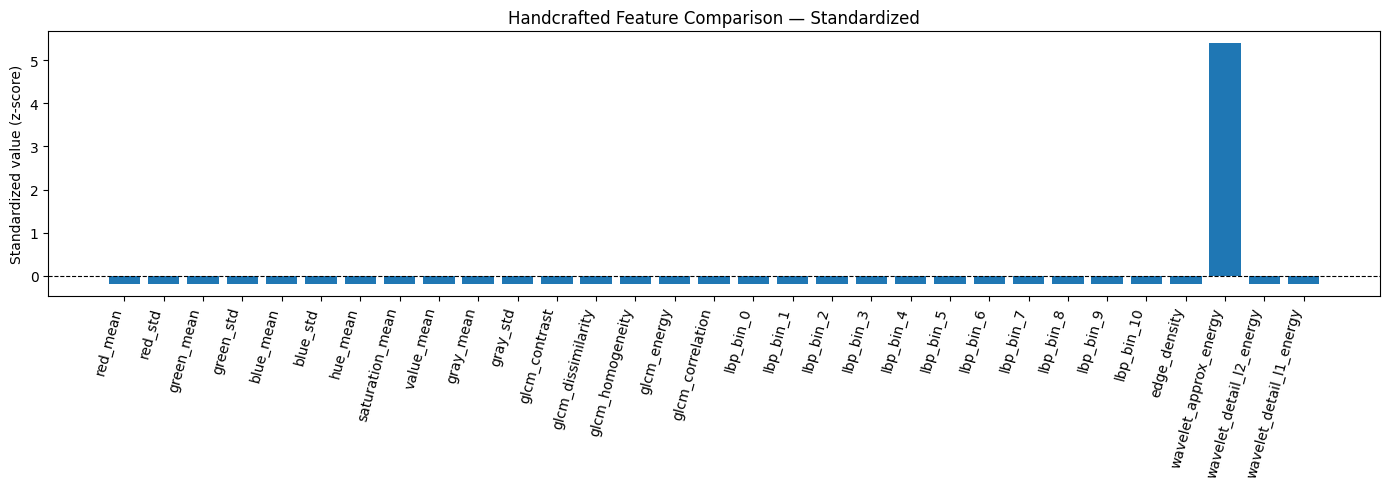

In [ ]:
import cv2
import numpy as np
import pandas as pd
import pywt
import matplotlib.pyplot as plt

from PIL import Image
from skimage.feature import (
    graycomatrix, graycoprops, local_binary_pattern
)

def extract_handcrafted_features(filepath):
    rgb_img = np.asarray(
        Image.open(filepath).convert("RGB").resize((128, 128))
    )
    gray_img = cv2.cvtColor(rgb_img, cv2.COLOR_RGB2GRAY)

    features = {}

    for i, channel in enumerate(["red", "green", "blue"]):
        features[f"{channel}_mean"] = float(
            rgb_img[:, :, i].mean()
        )
        features[f"{channel}_std"] = float(
            rgb_img[:, :, i].std()
        )

    hsv_img = cv2.cvtColor(rgb_img, cv2.COLOR_RGB2HSV)
    features["hue_mean"] = float(hsv_img[:, :, 0].mean())
    features["saturation_mean"] = float(hsv_img[:, :, 1].mean())
    features["value_mean"] = float(hsv_img[:, :, 2].mean())

    features["gray_mean"] = float(gray_img.mean())
    features["gray_std"] = float(gray_img.std())

    quantized = np.minimum(
        gray_img.astype(np.uint16) // 16, 15
    ).astype(np.uint8)

    # grey level cooccurance matrix
    glcm = graycomatrix(
        quantized,
        distances=[1],
        angles=[0, np.pi / 4, np.pi / 2, 3 * np.pi / 4],
        levels=16,
        symmetric=True,
        normed=True
    )

    for prop in ["contrast", "dissimilarity",
                 "homogeneity", "energy", "correlation"]:
        features[f"glcm_{prop}"] = float(
            graycoprops(glcm, prop).mean()
        )
    # local binary pattern
    lbp = local_binary_pattern(
        gray_img, P=8, R=1, method="uniform"
    )
    lbp_hist, _ = np.histogram(
        lbp.ravel(), bins=np.arange(0, 12),
        range=(0, 11), density=True
    )

    for i, value in enumerate(lbp_hist):
        features[f"lbp_bin_{i}"] = float(value)

    edges = cv2.Canny(gray_img, 50, 150)
    features["edge_density"] = float(np.mean(edges > 0))

    coeffs = pywt.wavedec2(
        gray_img.astype(np.float32),
        wavelet="db2",
        level=2
    )

    cA2 = coeffs[0]
    details_l2 = coeffs[1]
    details_l1 = coeffs[2]

    features["wavelet_approx_energy"] = float(np.mean(cA2 ** 2))
    features["wavelet_detail_l2_energy"] = float(
        np.mean([np.mean(c ** 2) for c in details_l2])
    )
    features["wavelet_detail_l1_energy"] = float(
        np.mean([np.mean(c ** 2) for c in details_l1])
    )

    return features

sample_row = project_df.iloc[0]

feature_vector = extract_handcrafted_features(
    sample_row["filepath"]
)

feature_df = pd.DataFrame({
    "Feature": list(feature_vector.keys()),
    "Value": list(feature_vector.values())
})

print("Sample:", sample_row["filename"])
print("Class:", sample_row["class_name"])
print("Number of extracted features:", len(feature_df))
display(feature_df.round(4))

values = feature_df["Value"].astype(float)

feature_df["Standardized Value"] = (
    (values - values.mean()) /
    (values.std() if values.std() != 0 else 1)
)

plt.figure(figsize=(14, 5))
plt.bar(feature_df["Feature"],
    feature_df["Standardized Value"]
)
plt.axhline(0, color="black", linestyle="--", linewidth=0.8)
plt.xticks(rotation=75, ha="right")
plt.ylabel("Standardized value (z-score)")
plt.title("Handcrafted Feature Comparison — Standardized")
plt.tight_layout()
plt.show()

# STEP 11A: PREPARE DATA FOR EFFICIENTNET-**B0**

In [ ]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(42)

split_groups = {
    "train": [],
    "validation": [],
    "test": []
}

# one source group per class for validation another group per class for testing
for class_name in PROJECT_CLASSES:
    class_groups = (
        project_df.loc[
            project_df["class_name"] == class_name,
            "source_group"
        ]
        .unique()
        .tolist()
    )

    class_groups = list(rng.permutation(class_groups))

    if len(class_groups) < 3:
        raise ValueError(
            f"{class_name} needs at least 3 source groups."
        )

    split_groups["test"].append(class_groups[0])
    split_groups["validation"].append(class_groups[1])
    split_groups["train"].extend(class_groups[2:])

# three DataFrames
train_df = project_df[
    project_df["source_group"].isin(split_groups["train"])
].copy()

val_df = project_df[
    project_df["source_group"].isin(split_groups["validation"])
].copy()

test_df = project_df[
    project_df["source_group"].isin(split_groups["test"])
].copy()

train_groups = set(train_df["source_group"])
val_groups = set(val_df["source_group"])
test_groups = set(test_df["source_group"])

assert train_groups.isdisjoint(val_groups)  #checking data leakage
assert train_groups.isdisjoint(test_groups)
assert val_groups.isdisjoint(test_groups)

split_summary = []

for split_name, split_df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    split_summary.append({
        "Split": split_name,
        "Images": len(split_df),
        "Source groups": split_df["source_group"].nunique()
    })

print("SOURCE-GROUPED DATA SPLIT")
display(pd.DataFrame(split_summary))

print("\nImages per class:")
display(pd.crosstab(
    project_df["class_name"],
    project_df["filepath"].map(
        lambda p: (
            "Train" if p in set(train_df["filepath"])
            else "Validation" if p in set(val_df["filepath"])
            else "Test"
        )
    )
).reindex(PROJECT_CLASSES))

print("\nLeakage check passed: no source group appears in multiple splits.")
print("Training groups:", sorted(train_groups))
print("Validation groups:", sorted(val_groups))
print("Test groups:", sorted(test_groups))

SOURCE-GROUPED DATA SPLIT


,Split,Images,Source groups
0,Train,8243,24
1,Validation,1589,5
2,Test,1745,5



Images per class:


filepath,Test,Train,Validation
class_name,,,
Class 1,314,932,335
Class 2,362,2030,307
Class 3,381,2104,309
Class 4,346,2214,337
Class 5,342,963,301



Leakage check passed: no source group appears in multiple splits.
Training groups: ['M0-LBA-AN', 'M1-LBA-AN', 'M10-LBA-AN', 'M11-LBA-AN', 'M12-LBA-AN', 'M13-LBA-AN', 'M14-LBA-AN', 'M15-LBA-AN', 'M16-LBA-AN', 'M17-LBA-AN', 'M18-LBA-AN', 'M22-LBA-AN', 'M23-LBA-AN', 'M24-LBA-AN', 'M25-LBA-AN', 'M27-LBA-AN', 'M28-LBA-AN', 'M3-LBA-AN', 'M31-LBA-AN', 'M32-LBA-AN', 'M33-LBA-AN', 'M5-LBA-AN', 'M6-LBA-AN', 'M7-LBA-AN']
Validation groups: ['M2-LBA-AN', 'M20-LBA-AN', 'M21-LBA-AN', 'M29-LBA-AN', 'M9-LBA-AN']
Test groups: ['M19-LBA-AN', 'M26-LBA-AN', 'M30-LBA-AN', 'M4-LBA-AN', 'M8-LBA-AN']


# **STEP 11B: EFFICIENTNET-B0 MODEL SETUP**

In [ ]:
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

if device.type == "cpu":
    print("WARNING: Enable a GPU in Colab before training for practical speed.")

IMAGE_SIZE = 244
BATCH_SIZE = 50
NUM_EPOCHS = 30
LEARNING_RATE = 0.0001
NUM_CLASSES = 5

imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std = [0.229, 0.224, 0.225]

image_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=imagenet_mean,
        std=imagenet_std
    )
])

class WaterTurbidityDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.data = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):
        row = self.data.iloc[index]

        with Image.open(row["filepath"]) as img:
            image = img.convert("RGB")

        if self.transform:
            image = self.transform(image)

        label = int(row["label"])
        return image, label


train_dataset = WaterTurbidityDataset(train_df, image_transform)
val_dataset = WaterTurbidityDataset(val_df, image_transform)
test_dataset = WaterTurbidityDataset(test_df, image_transform)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

# Loading EfficientNet B0
weights = EfficientNet_B0_Weights.DEFAULT
model = efficientnet_b0(weights=weights)

# Replacing the 1000 class ImageNet output with our 5 classes
model.classifier[1] = nn.Linear(
    model.classifier[1].in_features,
    NUM_CLASSES
)

# Fine tuning the entire network
for parameter in model.parameters():
    parameter.requires_grad = True

model = model.to(device)

# Loss and optimizer
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

print("\nMODEL CONFIGURATION")
print("Architecture: EfficientNet-B0")
print("Pretrained weights: ImageNet")
print("Trainable parameters:", sum(
    p.numel() for p in model.parameters() if p.requires_grad
))
print("Input size:", f"{IMAGE_SIZE} x {IMAGE_SIZE} x 3")
print("Classes:", PROJECT_CLASSES)
print("Batch size:", BATCH_SIZE)
print("Target epochs:", NUM_EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("Optimizer: Adam")
print("Loss: CrossEntropyLoss")

# 6. Verify one batch and output shape
images, labels = next(iter(train_loader))

print("\nBATCH VERIFICATION")
print("Image batch shape:", tuple(images.shape))
print("Label batch shape:", tuple(labels.shape))
print("Labels present in batch:", torch.unique(labels).tolist())

with torch.no_grad():
    model.eval()
    sample_outputs = model(images[:2].to(device))

print("Model output shape:", tuple(sample_outputs.shape))
model.train()

assert images.shape[1:] == (3, IMAGE_SIZE, IMAGE_SIZE)
assert sample_outputs.shape == (2, NUM_CLASSES)

print("\nSetup successful. The model is ready for training.")

Device: cuda
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 97.4MB/s]



MODEL CONFIGURATION
Architecture: EfficientNet-B0
Pretrained weights: ImageNet
Trainable parameters: 4013953
Input size: 244 x 244 x 3
Classes: ['Class 1', 'Class 2', 'Class 3', 'Class 4', 'Class 5']
Batch size: 50
Target epochs: 30
Learning rate: 0.0001
Optimizer: Adam
Loss: CrossEntropyLoss

BATCH VERIFICATION
Image batch shape: (50, 3, 244, 244)
Label batch shape: (50,)
Labels present in batch: [0, 1, 2, 3, 4]
Model output shape: (2, 5)

Setup successful. The model is ready for training.


In [ ]:
import torch
import time

print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None")

if torch.cuda.is_available():
    print("GPU memory allocated:",
          round(torch.cuda.memory_allocated() / 1024**3, 2), "GB")
    print("GPU memory reserved:",
          round(torch.cuda.memory_reserved() / 1024**3, 2), "GB")

start = time.time()
test_iterator = iter(train_loader)

for i in range(5):
    images, labels = next(test_iterator)
    print(f"Batch {i+1}: {images.shape}")

print("Time for 5 batches:", round(time.time() - start, 2), "seconds")

GPU: Tesla T4
GPU memory allocated: 0.02 GB
GPU memory reserved: 0.06 GB
Batch 1: torch.Size([50, 3, 244, 244])
Batch 2: torch.Size([50, 3, 244, 244])
Batch 3: torch.Size([50, 3, 244, 244])
Batch 4: torch.Size([50, 3, 244, 244])
Batch 5: torch.Size([50, 3, 244, 244])
Time for 5 batches: 50.53 seconds


# **OPTIMIZE DATA LOADING FOR GPU TRAINING**

In [ ]:
import shutil
import time
from pathlib import Path
from torch.utils.data import DataLoader

SOURCE_ROOT = Path("/content/drive/MyDrive/Dataset")
LOCAL_ROOT = Path("/content/Dataset")

# Copy images from Google Drive to Colab local storage
if not all((LOCAL_ROOT / c).is_dir() for c in PROJECT_CLASSES):
    print("Copying dataset to local storage...")
    shutil.copytree(SOURCE_ROOT, LOCAL_ROOT, dirs_exist_ok=True)

local_count = sum(
    1 for p in LOCAL_ROOT.rglob("*")
    if p.is_file() and p.suffix.lower() in {
        ".jpg", ".jpeg", ".png", ".bmp", ".webp"
    }
)

assert local_count >= len(project_df), (
    f"Expected at least {len(project_df)} images, found {local_count}"
)

for df in [project_df, train_df, val_df, test_df]:
    df["filepath"] = df["filepath"].map(
        lambda p: str(LOCAL_ROOT / Path(p).relative_to(SOURCE_ROOT))
    )

train_dataset = WaterTurbidityDataset(train_df, image_transform)
val_dataset = WaterTurbidityDataset(val_df, image_transform)
test_dataset = WaterTurbidityDataset(test_df, image_transform)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=4,
    pin_memory=True,
    persistent_workers=True,
    prefetch_factor=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=4,
    pin_memory=True,
    persistent_workers=True,
    prefetch_factor=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=4,
    pin_memory=True,
    persistent_workers=True,
    prefetch_factor=2
)

print("Local images available:", local_count)
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))

start = time.time()
iterator = iter(train_loader)

for i in range(5):
    images, labels = next(iterator)

print(f"Time for 5 batches: {time.time() - start:.2f} seconds")

Copying dataset to local storage...
Local images available: 11577
Training images: 8243
Validation images: 1589
Test images: 1745


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


Time for 5 batches: 2.42 seconds


# **STEP 11C: OPTIMIZED EFFICIENTNET-B0 TRAINING**

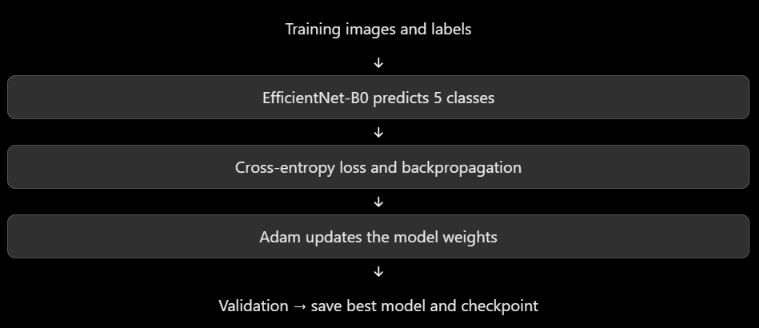

In [ ]:
import time
import torch
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from torch.utils.data import DataLoader
from tqdm.auto import tqdm
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=2, pin_memory=True,
    persistent_workers=True, prefetch_factor=2
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=2, pin_memory=True,
    persistent_workers=True, prefetch_factor=2
)

MODEL_DIR = Path("/content/drive/MyDrive/Turbidity_Model")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

BEST_MODEL_PATH = MODEL_DIR / "efficientnet_b0_grouped_best.pth"
LAST_CHECKPOINT_PATH = MODEL_DIR / "efficientnet_b0_grouped_last.pth"
HISTORY_PATH = MODEL_DIR / "efficientnet_b0_training_history.csv"

#Initialize clean pretrained model
model = efficientnet_b0(weights=EfficientNet_B0_Weights.DEFAULT)
model.classifier[1] = torch.nn.Linear(
    model.classifier[1].in_features, NUM_CLASSES
)
model = model.to(device)

criterion = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

use_amp = (device.type == "cuda")
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

history = []
start_epoch = 0
best_val_loss = float("inf")
best_epoch = 0

#Resume safely if an epoch checkpoint exists
if LAST_CHECKPOINT_PATH.exists():
    checkpoint = torch.load(
        LAST_CHECKPOINT_PATH, map_location=device, weights_only=False
    )
    model.load_state_dict(checkpoint["model_state_dict"])
    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
    scaler.load_state_dict(checkpoint["scaler_state_dict"])
    history = checkpoint["history"]
    start_epoch = checkpoint["epoch"]
    best_val_loss = checkpoint["best_val_loss"]
    best_epoch = checkpoint["best_epoch"]
    print(f"Resuming after completed epoch {start_epoch}")
else:
    print("Starting fresh from ImageNet pretrained weights.")

# Train and validate
for epoch in range(start_epoch, NUM_EPOCHS):
    epoch_start = time.time()

    model.train()
    train_loss_sum = train_correct = train_total = 0

    for images, labels in tqdm(
        train_loader, desc=f"Epoch {epoch+1}/{NUM_EPOCHS} — Train"
    ):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type=device.type, dtype=torch.float16, enabled=use_amp
        ):
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward() #model weights updation
        scaler.step(optimizer)
        scaler.update()

        n = labels.size(0)
        train_loss_sum += loss.item() * n
        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += n

    train_loss = train_loss_sum / train_total
    train_accuracy = train_correct / train_total

    model.eval()
    val_loss_sum = val_correct = val_total = 0

    with torch.no_grad():
        for images, labels in tqdm(
            val_loader, desc=f"Epoch {epoch+1}/{NUM_EPOCHS} — Validation"
        ):
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with torch.autocast(
                device_type=device.type, dtype=torch.float16, enabled=use_amp
            ):
                outputs = model(images)
                loss = criterion(outputs, labels)

            n = labels.size(0)
            val_loss_sum += loss.item() * n
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += n

    val_loss = val_loss_sum / val_total
    val_accuracy = val_correct / val_total

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy,
        "epoch_seconds": time.time() - epoch_start
    })

    # Save best model
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch + 1

        torch.save({
            "epoch": best_epoch,
            "model_state_dict": model.state_dict(),
            "best_val_loss": best_val_loss,
            "val_accuracy": val_accuracy,
            "classes": PROJECT_CLASSES,
            "image_size": IMAGE_SIZE,
            "imagenet_mean": imagenet_mean,
            "imagenet_std": imagenet_std
        }, BEST_MODEL_PATH)
        print("Best model checkpoint updated.")

    #Savingg resumable checkpoint after every completed epoch
    torch.save({
        "epoch": epoch + 1,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "history": history,
        "best_val_loss": best_val_loss,
        "best_epoch": best_epoch
    }, LAST_CHECKPOINT_PATH)

    pd.DataFrame(history).to_csv(HISTORY_PATH, index=False)

Resuming after completed epoch 30


# STEP 12: EVALUATE THE BEST EFFICIENTNET-B0 **MODEL**

Training epochs recorded: 30
Best checkpoint epoch: 1


,epoch,train_loss,train_accuracy,val_loss,val_accuracy,epoch_seconds
25,26,0.0072,0.9976,3.7327,0.6249,52.7998
26,27,0.0058,0.9985,3.5612,0.6130,53.3062
27,28,0.0011,0.9996,3.6385,0.5960,53.1178
28,29,0.0014,0.9998,4.0716,0.6010,52.7418
29,30,0.0005,0.9999,4.1209,0.6004,52.5944


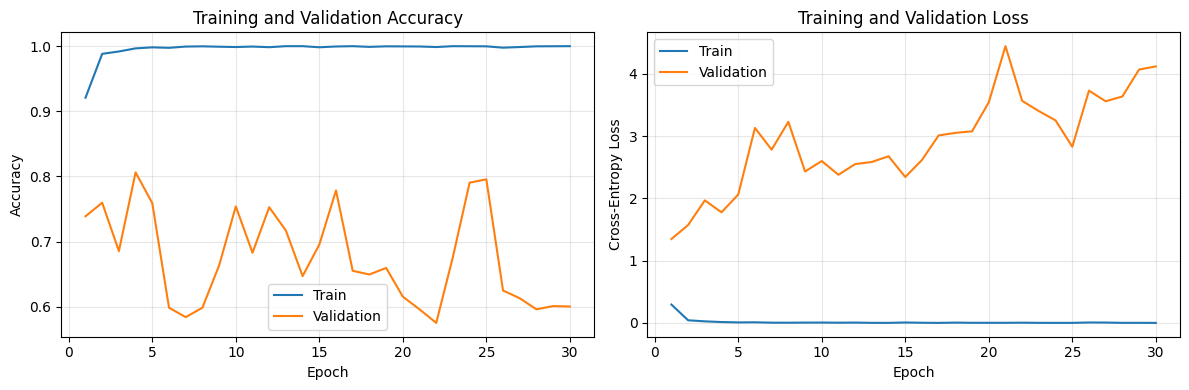

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()



HELD-OUT TEST RESULTS
Checkpoint epoch: 1
Best validation loss: 1.3481
Test images: 1745
Accuracy:  0.8774
Macro precision: 0.8960
Macro recall:    0.8744
Macro F1-score:  0.8767

CLASSIFICATION REPORT
              precision    recall  f1-score   support

     Class 1     1.0000    0.7229    0.8392       314
     Class 2     0.7298    0.6492    0.6871       362
     Class 3     0.7500    1.0000    0.8571       381
     Class 4     1.0000    1.0000    1.0000       346
     Class 5     1.0000    1.0000    1.0000       342

    accuracy                         0.8774      1745
   macro avg     0.8960    0.8744    0.8767      1745
weighted avg     0.8894    0.8774    0.8750      1745



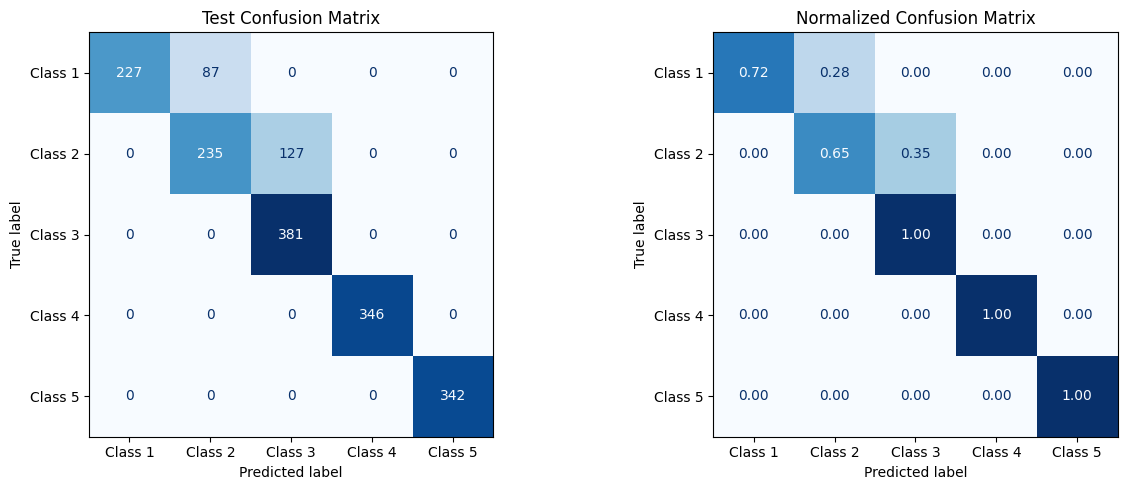

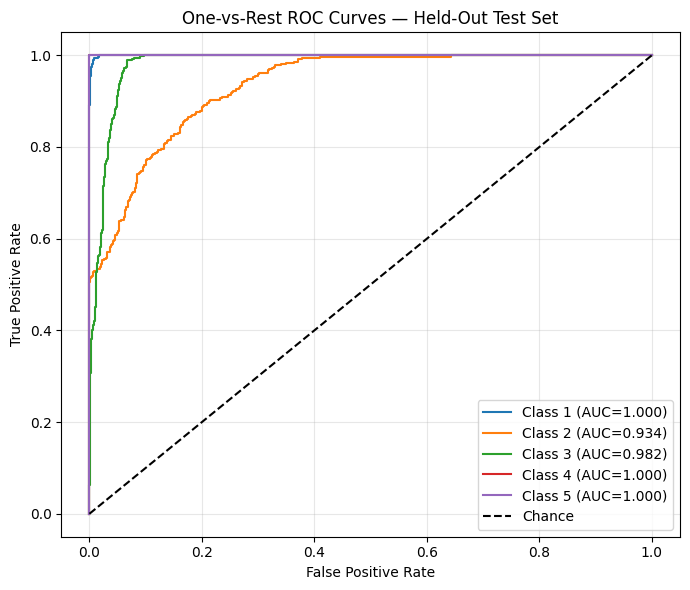

Macro ROC-AUC: 0.9832

Saved predictions to: /content/drive/MyDrive/Turbidity_Model/efficientnet_b0_test_predictions.csv
Evaluation complete.


In [ ]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from torchvision.models import efficientnet_b0
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    auc
)
from sklearn.preprocessing import label_binarize

MODEL_DIR = Path("/content/drive/MyDrive/Turbidity_Model")
BEST_MODEL_PATH = MODEL_DIR / "efficientnet_b0_grouped_best.pth"
HISTORY_PATH = MODEL_DIR / "efficientnet_b0_training_history.csv"

if not BEST_MODEL_PATH.exists():
    raise FileNotFoundError(f"Best checkpoint not found: {BEST_MODEL_PATH}")

history_df = pd.read_csv(HISTORY_PATH)

print("Training epochs recorded:", len(history_df))
print("Best checkpoint epoch:", int(
    torch.load(
        BEST_MODEL_PATH, map_location="cpu", weights_only=False
    )["epoch"]
))
display(history_df.tail().round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history_df["epoch"], history_df["train_accuracy"], label="Train")
axes[0].plot(history_df["epoch"], history_df["val_accuracy"], label="Validation")
axes[0].set_title("Training and Validation Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(history_df["epoch"], history_df["train_loss"], label="Train")
axes[1].plot(history_df["epoch"], history_df["val_loss"], label="Validation")
axes[1].set_title("Training and Validation Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Cross-Entropy Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

checkpoint = torch.load(
    BEST_MODEL_PATH, map_location=device, weights_only=False
)

model = efficientnet_b0(weights=None)
model.classifier[1] = torch.nn.Linear(
    model.classifier[1].in_features, NUM_CLASSES
)
model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(device)
model.eval()

all_labels = []
all_predictions = []
all_probabilities = []

use_amp = device.type == "cuda"

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device, non_blocking=True)

        with torch.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=use_amp
        ):
            logits = model(images)

        probabilities = torch.softmax(logits.float(), dim=1)
        predictions = probabilities.argmax(dim=1)

        all_labels.extend(labels.numpy().tolist())
        all_predictions.extend(predictions.cpu().numpy().tolist())
        all_probabilities.extend(probabilities.cpu().numpy())

y_true = np.asarray(all_labels)
y_pred = np.asarray(all_predictions)
y_prob = np.asarray(all_probabilities)

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(
    y_true, y_pred, average="macro", zero_division=0
)
recall = recall_score(
    y_true, y_pred, average="macro", zero_division=0
)
macro_f1 = f1_score(
    y_true, y_pred, average="macro", zero_division=0
)

print("\nHELD-OUT TEST RESULTS")
print("Checkpoint epoch:", checkpoint["epoch"])
print("Best validation loss:", round(checkpoint["best_val_loss"], 4))
print("Test images:", len(y_true))
print(f"Accuracy:  {accuracy:.4f}")
print(f"Macro precision: {precision:.4f}")
print(f"Macro recall:    {recall:.4f}")
print(f"Macro F1-score:  {macro_f1:.4f}")

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=PROJECT_CLASSES,
    digits=4,
    zero_division=0
))

cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=PROJECT_CLASSES
).plot(ax=axes[0], cmap="Blues", values_format="d", colorbar=False)
axes[0].set_title("Test Confusion Matrix")

row_sums = cm.sum(axis=1, keepdims=True)
normalized_cm = np.divide(
    cm, row_sums,
    out=np.zeros_like(cm, dtype=float),
    where=row_sums != 0
)

ConfusionMatrixDisplay(
    confusion_matrix=normalized_cm,
    display_labels=PROJECT_CLASSES
).plot(ax=axes[1], cmap="Blues", values_format=".2f", colorbar=False)
axes[1].set_title("Normalized Confusion Matrix")

plt.tight_layout()
plt.show()

y_true_binary = label_binarize(y_true, classes=list(range(NUM_CLASSES)))
auc_values = []

plt.figure(figsize=(7, 6))

for i, class_name in enumerate(PROJECT_CLASSES):
    if len(np.unique(y_true_binary[:, i])) < 2:
        print(f"ROC-AUC unavailable for {class_name}.")
        continue

    fpr, tpr, _ = roc_curve(y_true_binary[:, i], y_prob[:, i])
    class_auc = auc(fpr, tpr)
    auc_values.append(class_auc)
    plt.plot(fpr, tpr, label=f"{class_name} (AUC={class_auc:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Chance")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("One-vs-Rest ROC Curves — Held-Out Test Set")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

if len(auc_values) == NUM_CLASSES:
    macro_auc = roc_auc_score(
        y_true_binary, y_prob, average="macro"
    )
    print(f"Macro ROC-AUC: {macro_auc:.4f}")

test_results = test_df.reset_index(drop=True).copy()
test_results["true_class"] = [PROJECT_CLASSES[i] for i in y_true]
test_results["predicted_class"] = [PROJECT_CLASSES[i] for i in y_pred]
test_results["correct"] = y_true == y_pred

for i, class_name in enumerate(PROJECT_CLASSES):
    test_results[f"prob_{class_name.replace(' ', '_')}"] = y_prob[:, i]

test_results.to_csv(MODEL_DIR / "efficientnet_b0_test_predictions.csv", index=False)

print("\nSaved predictions to:", MODEL_DIR / "efficientnet_b0_test_predictions.csv")
print("Evaluation complete.")

# **STEP 13: UPLOAD AN IMAGE AND PREDICT TURBIDITY CLASS**

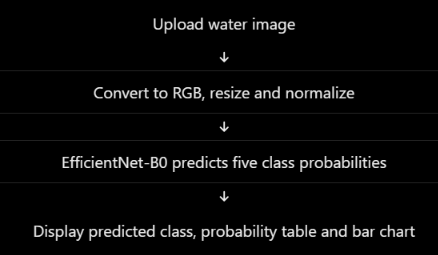

Saving image_2026-10-23_121009377.png to image_2026-10-23_121009377.png


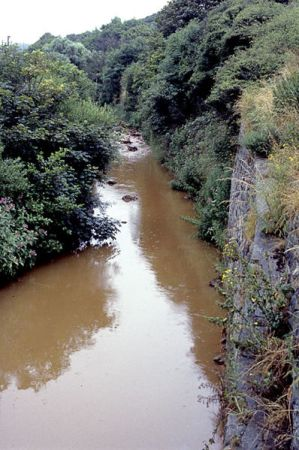

Predicted class: Class 3
Best checkpoint epoch: 1


,Class,Probability
2,Class 3,100.00%
1,Class 2,0.00%
0,Class 1,0.00%
3,Class 4,0.00%
4,Class 5,0.00%


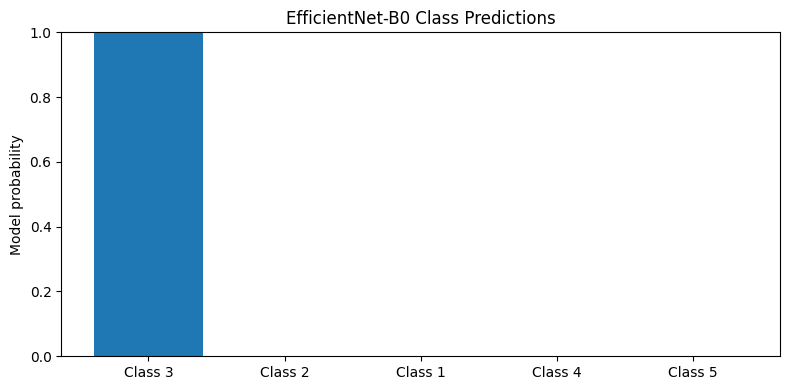

In [ ]:
from google.colab import files
from PIL import Image
from IPython.display import display
import torch
import pandas as pd
import matplotlib.pyplot as plt

checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=device,
    weights_only=False
)

model = efficientnet_b0(weights=None)
model.classifier[1] = torch.nn.Linear(
    model.classifier[1].in_features,
    NUM_CLASSES
)
model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(device)
model.eval()

uploaded = files.upload()

if not uploaded:
    raise ValueError("Please upload an image.")

filename = next(iter(uploaded))

with Image.open(filename) as im:
    input_image = im.convert("RGB")

display(input_image)

input_tensor = image_transform(input_image).unsqueeze(0).to(device)

with torch.no_grad():
    logits = model(input_tensor)
    probabilities = torch.softmax(logits.float(), dim=1)[0].cpu().numpy()

predicted_idx = int(probabilities.argmax())

print("Predicted class:", PROJECT_CLASSES[predicted_idx])
print("Best checkpoint epoch:", checkpoint["epoch"])

probability_df = pd.DataFrame({
    "Class": PROJECT_CLASSES,
    "Probability": probabilities
}).sort_values("Probability", ascending=False)

display(probability_df.style.format({"Probability": "{:.2%}"}))

plt.figure(figsize=(8, 4))
plt.bar(probability_df["Class"], probability_df["Probability"])
plt.ylabel("Model probability")
plt.title("EfficientNet-B0 Class Predictions")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

## **RIVER IMAGE SEGMENTATION and MODEL TEST**

via Morphological closing

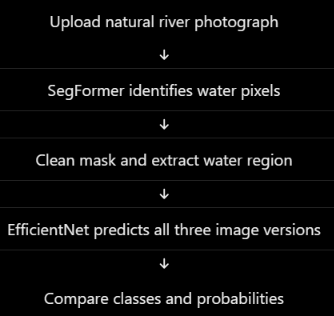

Saving image_2026-10-23_122221377.png to image_2026-10-23_122221377.png
Image: image_2026-10-23_122221377.png
Image dimensions: 1280 x 853


Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

Segmentation label: water (ID: 21 )
Raw predicted water pixels: 17.45%
Retained water pixels: 17.28%


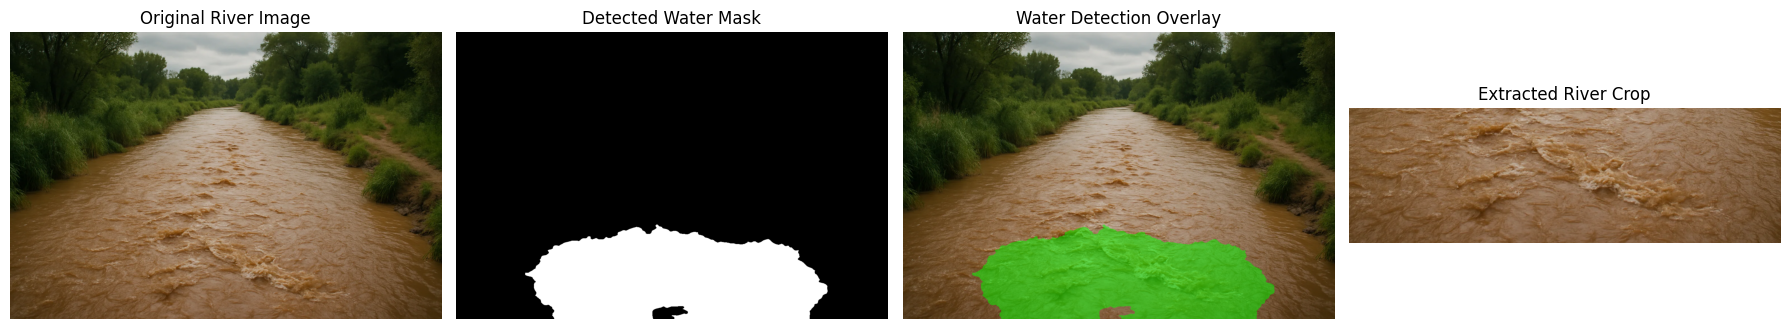

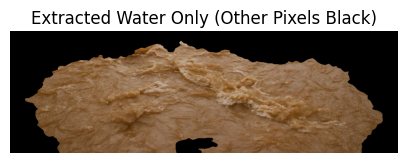


PREDICTION COMPARISON


,Input version,Predicted class,Model probability
0,Full image,Class 1,85.89%
1,River crop,Class 5,72.63%
2,Masked river crop,Class 4,99.67%



CLASS PROBABILITIES


Class,Class 1,Class 2,Class 3,Class 4,Class 5
Input version,,,,,
Full image,85.89%,2.06%,2.09%,0.49%,9.47%
Masked river crop,0.00%,0.05%,0.27%,99.67%,0.01%
River crop,13.18%,1.62%,8.75%,3.82%,72.63%



IMPORTANT: These are exploratory predictions. SegFormer can confuse water with shadows, reflections or vegetation. The classifier was trained on laboratory samples, so these results do not validate real-world turbidity estimation.


In [ ]:
!pip -q install transformers

import io
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

from PIL import Image
from google.colab import files
from IPython.display import display as show_table
from transformers import (
    SegformerImageProcessor,
    SegformerForSemanticSegmentation
)
from torchvision.models import efficientnet_b0

uploaded = files.upload()
if not uploaded:
    raise ValueError("Please upload a river photograph.")

filename = next(iter(uploaded))
river_image = Image.open(
    io.BytesIO(uploaded[filename])
).convert("RGB")

river_image.thumbnail((1280, 1280))
rgb = np.array(river_image)
height, width = rgb.shape[:2]

print("Image:", filename)
print("Image dimensions:", width, "x", height)

# pretrained water scene segmentation model
SEG_MODEL_NAME = "nvidia/segformer-b0-finetuned-ade-512-512"

seg_processor = SegformerImageProcessor.from_pretrained(
    SEG_MODEL_NAME
)
segmenter = SegformerForSemanticSegmentation.from_pretrained(
    SEG_MODEL_NAME
).to(device)
segmenter.eval()

id2label = segmenter.config.id2label
water_candidates = [
    (int(k), str(v))
    for k, v in id2label.items()
    if "water" in str(v).lower()
]

exact_water = [
    (idx, name) for idx, name in water_candidates
    if name.strip().lower() == "water"
]

if exact_water:
    water_id, water_name = exact_water[0]
elif water_candidates:
    water_id, water_name = water_candidates[0]
else:
    raise ValueError("This segmentation model has no water class.")

print("Segmentation label:", water_name, "(ID:", water_id, ")")

inputs = seg_processor(
    images=river_image, return_tensors="pt"
)
inputs = {k: v.to(device) for k, v in inputs.items()}

with torch.no_grad():
    seg_output = segmenter(**inputs)

seg_logits = F.interpolate(
    seg_output.logits,
    size=(height, width),
    mode="bilinear",
    align_corners=False
)
seg_map = seg_logits.argmax(dim=1)[0].cpu().numpy()
raw_mask = seg_map == water_id

raw_percentage = raw_mask.mean() * 100
print(f"Raw predicted water pixels: {raw_percentage:.2f}%")

if raw_mask.sum() == 0:
    raise ValueError(
        "No water pixels detected. Segmentation cannot produce a reliable crop."
    )

# clean small gaps and keep the largest connected water region
mask_uint8 = raw_mask.astype(np.uint8) * 255
kernel = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE, (7, 7)
)
closed_mask = cv2.morphologyEx(
    mask_uint8, cv2.MORPH_CLOSE, kernel
)

num_labels, component_labels, stats, _ = (
    cv2.connectedComponentsWithStats(
        (closed_mask > 0).astype(np.uint8), connectivity=8
    )
)

if num_labels > 1:
    largest_component = 1 + np.argmax(
        stats[1:, cv2.CC_STAT_AREA]
    )
    water_mask = component_labels == largest_component
else:
    water_mask = raw_mask

print(f"Retained water pixels: {water_mask.mean() * 100:.2f}%")

ys, xs = np.where(water_mask)
pad_x = max(5, int(width * 0.03))
pad_y = max(5, int(height * 0.03))

x1 = max(0, xs.min() - pad_x)
x2 = min(width, xs.max() + 1 + pad_x)
y1 = max(0, ys.min() - pad_y)
y2 = min(height, ys.max() + 1 + pad_y)

river_crop = rgb[y1:y2, x1:x2].copy()
crop_mask = water_mask[y1:y2, x1:x2]
masked_crop = river_crop.copy()
masked_crop[~crop_mask] = 0

overlay = rgb.copy()
green = np.zeros_like(overlay)
green[:, :, 1] = 255
overlay[water_mask] = (
    0.5 * overlay[water_mask] +
    0.5 * green[water_mask]
).astype(np.uint8)

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
views = [
    ("Original River Image", rgb),
    ("Detected Water Mask", water_mask.astype(np.uint8) * 255),
    ("Water Detection Overlay", overlay),
    ("Extracted River Crop", river_crop)
]

for ax, (title, img) in zip(axes, views):
    ax.imshow(img, cmap="gray" if img.ndim == 2 else None)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

plt.figure(figsize=(5, 5))
plt.imshow(masked_crop)
plt.title("Extracted Water Only (Other Pixels Black)")
plt.axis("off")
plt.show()

MODEL_DIR = "/content/drive/MyDrive/Turbidity_Model"
ORIGINAL_CHECKPOINT = (
    f"{MODEL_DIR}/efficientnet_b0_grouped_best.pth"
)

checkpoint = torch.load(
    ORIGINAL_CHECKPOINT,
    map_location=device,
    weights_only=False
)

river_model = efficientnet_b0(weights=None)
river_model.classifier[1] = nn.Linear(
    river_model.classifier[1].in_features, NUM_CLASSES
)
river_model.load_state_dict(checkpoint["model_state_dict"])
river_model.to(device).eval()

test_images = {
    "Full image": Image.fromarray(rgb),
    "River crop": Image.fromarray(river_crop),
    "Masked river crop": Image.fromarray(masked_crop)
}

comparison = []
probability_rows = []

for name, pil_image in test_images.items():
    tensor = image_transform(pil_image).unsqueeze(0).to(device)

    with torch.no_grad():
        with torch.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=(device.type == "cuda")
        ):
            logits = river_model(tensor)

        probs = torch.softmax(logits.float(), dim=1)[0].cpu().numpy()

    pred = int(np.argmax(probs))

    comparison.append({
        "Input version": name,
        "Predicted class": PROJECT_CLASSES[pred],
        "Model probability": float(probs[pred])
    })

    for i, cls in enumerate(PROJECT_CLASSES):
        probability_rows.append({
            "Input version": name,
            "Class": cls,
            "Probability": float(probs[i])
        })

print("\nPREDICTION COMPARISON")
show_table(
    pd.DataFrame(comparison).style.format(
        {"Model probability": "{:.2%}"}
    )
)

print("\nCLASS PROBABILITIES")
prob_df = pd.DataFrame(probability_rows)
show_table(
    prob_df.pivot(
        index="Input version",
        columns="Class",
        values="Probability"
    ).style.format("{:.2%}")
)

print(
    "\nIMPORTANT: These are exploratory predictions. "
    "SegFormer can confuse water with shadows, reflections or vegetation. "
    "The classifier was trained on laboratory samples, so these results "
    "do not validate real-world turbidity estimation."
)

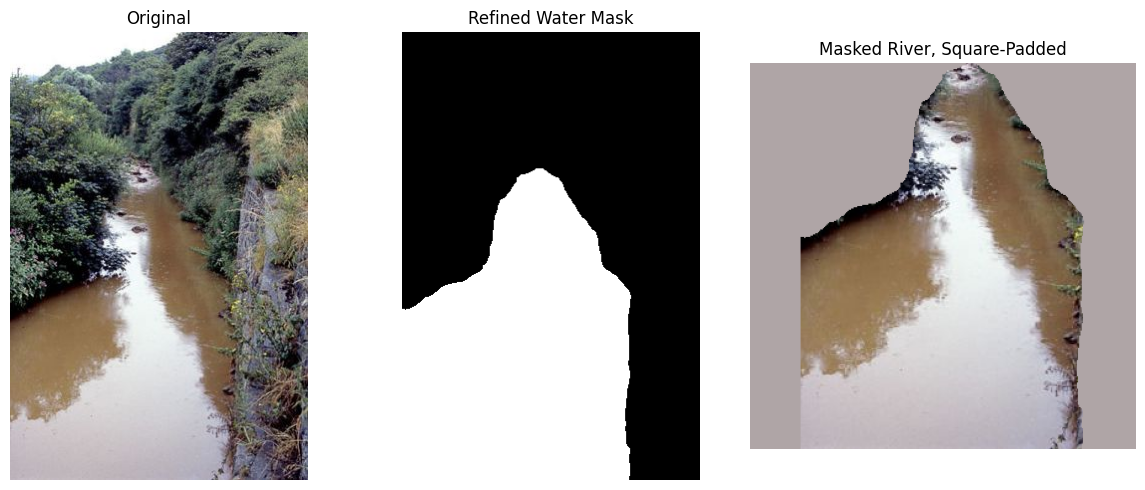

,Input,Predicted class,Top probability
0,Full image,Class 3,100.00%
1,Original river crop,Class 3,100.00%
2,Refined masked river,Class 3,100.00%


Exploratory comparison only: this does not validate river turbidity.


In [ ]:
# IMPROVED RIVER EXTRACTION AND PREDICTION

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# 1. Shrink the mask to reduce incorrectly included boundaries
mask_u8 = water_mask.astype(np.uint8)

kernel = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE, (5, 5)
)
clean_mask = cv2.erode(mask_u8, kernel, iterations=1).astype(bool)

if clean_mask.sum() == 0:
    raise ValueError("Mask became empty. Use the original water_mask.")

# 2. Crop tightly around the refined river mask
ys, xs = np.where(clean_mask)
y1, y2 = ys.min(), ys.max() + 1
x1, x2 = xs.min(), xs.max() + 1

crop_rgb = rgb[y1:y2, x1:x2].copy()
crop_mask = clean_mask[y1:y2, x1:x2]

# Replace excluded scenery with the median RGB of detected water
water_pixels = rgb[clean_mask]
fill_color = np.median(water_pixels, axis=0).astype(np.uint8)

masked_rgb = crop_rgb.copy()
masked_rgb[~crop_mask] = fill_color

def pad_to_square(image, fill):
    """Pad rather than distort the image aspect ratio."""
    h, w = image.shape[:2]
    side = max(h, w)

    canvas = np.empty((side, side, 3), dtype=np.uint8)
    canvas[:] = fill

    top = (side - h) // 2
    left = (side - w) // 2
    canvas[top:top+h, left:left+w] = image

    return canvas

square_river = pad_to_square(masked_rgb, fill_color)

# 3. Visualize extraction
fig, axes = plt.subplots(1, 3, figsize=(12, 5))

axes[0].imshow(rgb)
axes[0].set_title("Original")
axes[1].imshow(clean_mask, cmap="gray")
axes[1].set_title("Refined Water Mask")
axes[2].imshow(square_river)
axes[2].set_title("Masked River, Square-Padded")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

# 4. Compare predictions using the original trained model
inputs_to_test = {
    "Full image": Image.fromarray(rgb),
    "Original river crop": Image.fromarray(river_crop),
    "Refined masked river": Image.fromarray(square_river)
}

results = []

river_model.eval()

for name, pil_img in inputs_to_test.items():
    tensor = image_transform(pil_img).unsqueeze(0).to(device)

    with torch.no_grad():
        with torch.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=(device.type == "cuda")
        ):
            logits = river_model(tensor)

        probs = torch.softmax(logits.float(), dim=1)[0].cpu().numpy()

    results.append({
        "Input": name,
        "Predicted class": PROJECT_CLASSES[int(probs.argmax())],
        "Top probability": float(probs.max())
    })

display(pd.DataFrame(results).style.format({
    "Top probability": "{:.2%}"
}))

print("Exploratory comparison only: this does not validate river turbidity.")

*This project explored digital image processing techniques for river water turbidity classification, including image enhancement, denoising, color analysis, wavelet transforms, segmentation, and handcrafted feature extraction. EfficientNet-B0 achieved promising results on the held-out test dataset, demonstrating the potential of deep learning for classifying turbidity levels. However, testing on natural river images revealed limitations due to differences between laboratory samples and real-world conditions. Future work should focus on validating the model using real river images with measured NTU values to improve reliability and practical applicability.*
